# **Poverty and Inequality Analysis Using World Bank Data**

**Dataset:** `PovStatsEXCEL.xlsx`  
**Focus:** Poverty and income inequality trends in India  
**Tools:** Python, Pandas, Matplotlib, Excel

> This notebook analyses selected poverty and inequality indicators for India using the World Bank dataset. The dataset contains country-level indicators observed over multiple years. Many observations are missing because household-survey indicators are not measured every year; therefore, the analysis uses the years for which values are available rather than treating missing values as zero.

**Statistical techniques included:** descriptive statistics, frequency and relative-frequency tables, Pearson correlation, paired-observation counts, scatter plots with fitted trend lines, and first-versus-latest comparisons.

## 1. Introduction

Poverty and income inequality are important measures of a country's economic and social development. Poverty indicators show the proportion of people living below a specified poverty line, while inequality indicators describe how income or consumption is distributed among the population.

This project uses the World Bank Poverty and Inequality dataset to examine selected indicators for India. The analysis focuses on:

- Poverty headcount ratio at **$3.20 a day (2011 PPP)**.
- Poverty headcount ratio at **national poverty lines**.
- **Gini index**, which measures income or consumption inequality.
- Income share held by the **lowest 20%** of the population.

The purpose is to summarise the available observations, visualise changes over time, and interpret the trends. The analysis is descriptive and does not establish the causes of changes in poverty or inequality.

## 2. Problem Statement

Poverty and inequality can change over time due to economic, social, demographic and policy-related factors. However, understanding these changes requires examining reliable data across different years.

The problem addressed in this project is to understand what the available World Bank data indicate about poverty and income inequality in India.

The analysis attempts to answer the following questions:

1. How has the poverty headcount ratio at $3.20 a day (2011 PPP) changed across the available survey years?
2. How has the poverty headcount ratio measured using India's national poverty line changed?
3. What pattern is visible in the Gini index over the available years?
4. How has the income share held by the lowest 20% changed?
5. What do these indicators collectively suggest about poverty reduction and income distribution?

**Scope and limitations:** The dataset contains many countries, indicators and years, but several values are missing. Poverty and inequality observations are often based on household surveys and are not necessarily available annually. The analysis therefore uses only available observations for India. The selected indicators use different definitions and poverty thresholds, so their values should not be directly treated as interchangeable.

## 3. Method

The following steps are used:

1. **Load the dataset:** Read the `Data` worksheet from the Excel workbook using Pandas.
2. **Inspect the structure:** Check the number of rows and columns, column names, data types and missing values.
3. **Prepare the data:** Identify year columns, select India's records, and convert the wide year-based format into a long format with `Year` and `Value` columns.
4. **Select indicators:** Extract the four poverty and inequality indicators listed in the introduction.
5. **Summarise:** Display available observations and calculate the first-to-last change for each indicator.
6. **Visualise:** Create line charts to show the available observations over time.
7. **Interpret:** Describe the direction of change while considering missing years and differences in indicator definitions.

The notebook does not fill missing observations with zero or invent values for years that are not present.

In [1]:
# Import the required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Read the Excel workbook.
# Keep PovStatsEXCEL.xlsx in the same folder as this notebook.
file_path = "PovStatsEXCEL.xlsx"

# If running in Google Colab and the file is not present, upload it.
from pathlib import Path
if not Path(file_path).exists():
    try:
        from google.colab import files
        uploaded = files.upload()
        file_path = next(iter(uploaded))
    except ImportError:
        raise FileNotFoundError(
            "Place PovStatsEXCEL.xlsx in the notebook folder and run this cell again."
        )

# Load the main data worksheet
data = pd.read_excel(file_path, sheet_name="Data")

print("Dataset loaded successfully.")
print("Shape:", data.shape)
display(data.head())

Saving PovStatsEXCEL.xlsx to PovStatsEXCEL.xlsx
Dataset loaded successfully.
Shape: (13068, 51)


,Country Name,Country Code,Indicator Name,Indicator Code,1974,1975,1976,1977,1978,1979,...,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020
0,East Asia & Pacific,EAS,Annualized growth in per capita real survey me...,SI.SPR.PC40.ZG,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,East Asia & Pacific,EAS,Annualized growth in per capita real survey me...,SI.SPR.PT10.ZG,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,East Asia & Pacific,EAS,Annualized growth in per capita real survey me...,SI.SPR.PT60.ZG,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,East Asia & Pacific,EAS,Annualized growth in per capita real survey me...,SI.SPR.PCAP.ZG,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,East Asia & Pacific,EAS,Annualized growth in per capita real survey me...,SI.POV.XPND.MD.ZG,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [2]:
# Inspect dataset structure and data quality
print("Column names:")
print(data.columns.tolist())

print("\\nDataset information:")
data.info()

print("\\nNumber of missing values in the first columns:")
display(data.isnull().sum().head(10))

print("\\nNumber of countries:", data["Country Name"].nunique())
print("Number of indicators:", data["Indicator Name"].nunique())

# Identify columns whose names are years
year_columns = [col for col in data.columns if str(col).isdigit()]
print("Year range in the dataset:", year_columns[0], "to", year_columns[-1])
print("Number of year columns:", len(year_columns))

Column names:
['Country Name', 'Country Code', 'Indicator Name', 'Indicator Code', '1974', '1975', '1976', '1977', '1978', '1979', '1980', '1981', '1982', '1983', '1984', '1985', '1986', '1987', '1988', '1989', '1990', '1991', '1992', '1993', '1994', '1995', '1996', '1997', '1998', '1999', '2000', '2001', '2002', '2003', '2004', '2005', '2006', '2007', '2008', '2009', '2010', '2011', '2012', '2013', '2014', '2015', '2016', '2017', '2018', '2019', '2020']
\nDataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13068 entries, 0 to 13067
Data columns (total 51 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Country Name    13068 non-null  object 
 1   Country Code    13068 non-null  object 
 2   Indicator Name  13068 non-null  object 
 3   Indicator Code  13068 non-null  object 
 4   1974            223 non-null    float64
 5   1975            223 non-null    float64
 6   1976            189 non-null    float64
 7  

,0
Country Name,0
Country Code,0
Indicator Name,0
Indicator Code,0
1974,12845
1975,12845
1976,12879
1977,12870
1978,12862
1979,12794


\nNumber of countries: 198
Number of indicators: 66
Year range in the dataset: 1974 to 2020
Number of year columns: 47


In [3]:
# Select the four indicators for India
selected_indicators = [
    "Poverty headcount ratio at $3.20 a day (2011 PPP) (% of population)",
    "Poverty headcount ratio at national poverty lines (% of population)",
    "Gini index (World Bank estimate)",
    "Income share held by lowest 20%"
]

india = data[data["Country Name"] == "India"].copy()

# Convert year columns from wide format to long format
india_long = india.melt(
    id_vars=["Country Name", "Country Code", "Indicator Name", "Indicator Code"],
    value_vars=year_columns,
    var_name="Year",
    value_name="Value"
)

india_long["Year"] = pd.to_numeric(india_long["Year"], errors="coerce")
india_long["Value"] = pd.to_numeric(india_long["Value"], errors="coerce")

# Keep only the selected indicators and available observations
analysis_data = india_long[
    india_long["Indicator Name"].isin(selected_indicators)
].dropna(subset=["Value"]).sort_values(["Indicator Name", "Year"])

print("Available observations for India:")
display(analysis_data[["Indicator Name", "Year", "Value"]].reset_index(drop=True))

Available observations for India:


,Indicator Name,Year,Value
0,Gini index (World Bank estimate),1983,32.1
1,Gini index (World Bank estimate),1987,32.6
2,Gini index (World Bank estimate),1993,31.7
3,Gini index (World Bank estimate),2004,34.4
4,Gini index (World Bank estimate),2009,35.4
5,Gini index (World Bank estimate),2011,35.7
6,Income share held by lowest 20%,1983,8.5
7,Income share held by lowest 20%,1987,8.7
8,Income share held by lowest 20%,1993,8.9
9,Income share held by lowest 20%,2004,8.5


In [4]:
# Create a summary table for each selected indicator
summary_rows = []

for indicator in selected_indicators:
    subset = analysis_data[analysis_data["Indicator Name"] == indicator].sort_values("Year")

    if not subset.empty:
        first = subset.iloc[0]
        last = subset.iloc[-1]
        summary_rows.append({
            "Indicator": indicator,
            "First available year": int(first["Year"]),
            "First value": first["Value"],
            "Latest available year": int(last["Year"]),
            "Latest value": last["Value"],
            "Change": last["Value"] - first["Value"],
            "Number of observations": len(subset)
        })

summary = pd.DataFrame(summary_rows)
display(summary.round(2))

,Indicator,First available year,First value,Latest available year,Latest value,Change,Number of observations
0,Poverty headcount ratio at $3.20 a day (2011 P...,1977,88.7,2011,61.7,-27.0,7
1,Poverty headcount ratio at national poverty li...,1993,45.3,2011,21.9,-23.4,4
2,Gini index (World Bank estimate),1983,32.1,2011,35.7,3.6,6
3,Income share held by lowest 20%,1983,8.5,2011,8.1,-0.4,6


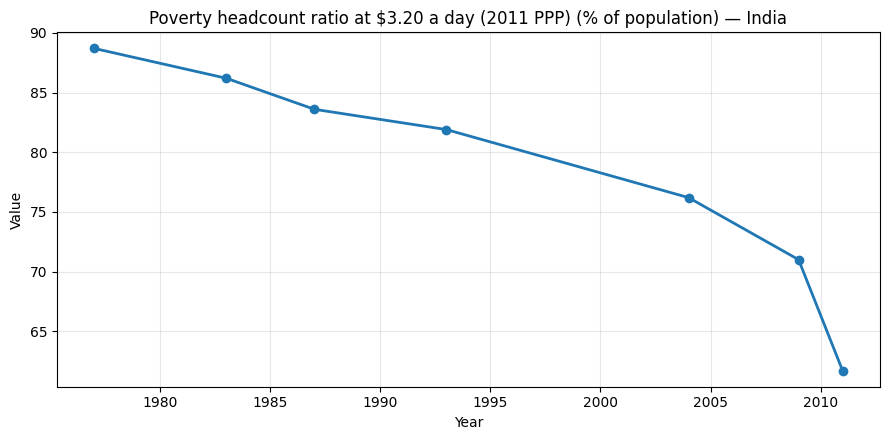

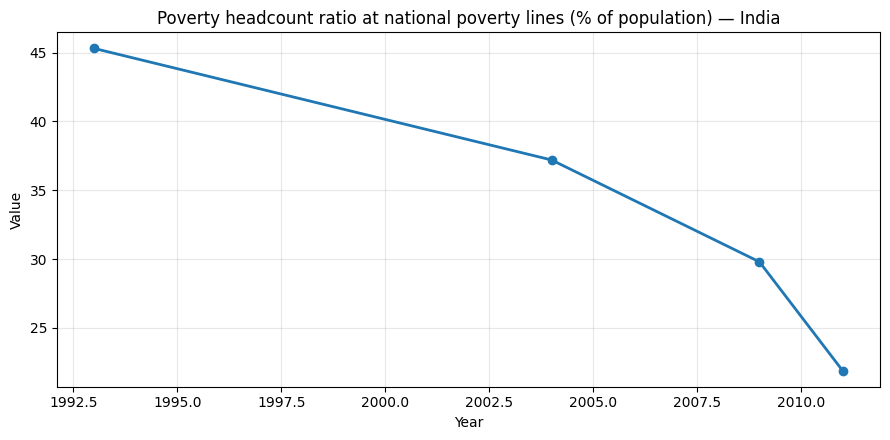

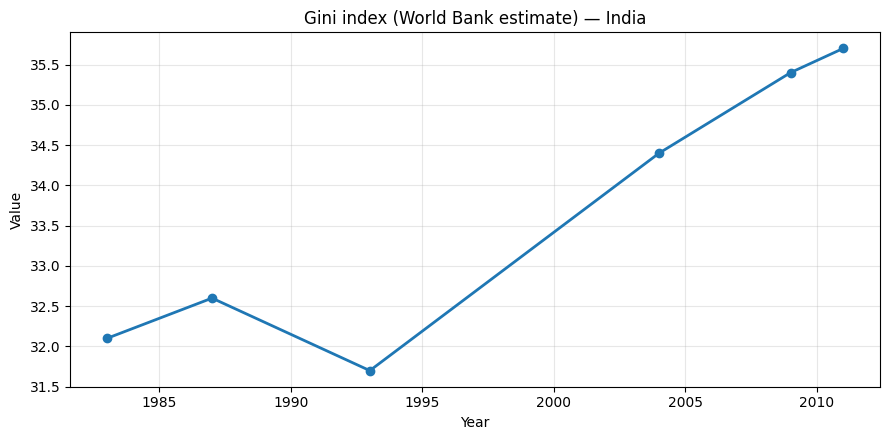

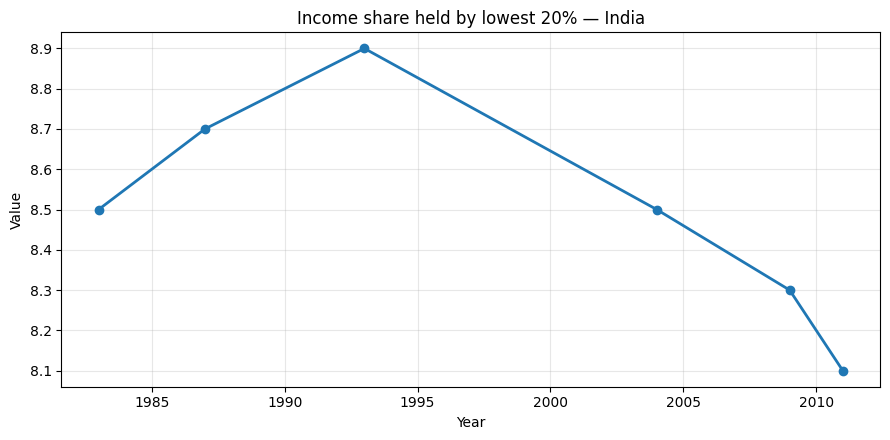

In [5]:
# Visualise each indicator separately
for indicator in selected_indicators:
    subset = analysis_data[analysis_data["Indicator Name"] == indicator].sort_values("Year")

    if not subset.empty:
        plt.figure(figsize=(9, 4.5))
        plt.plot(subset["Year"], subset["Value"], marker="o", linewidth=2)
        plt.title(indicator + " — India")
        plt.xlabel("Year")
        plt.ylabel("Value")
        plt.grid(True, alpha=0.3)
        plt.tight_layout()
        plt.show()


## 4. Statistical Analysis: Descriptive Measures, Frequency Distribution and Correlation

This section strengthens the analysis using standard statistical techniques. Since the dataset contains observations for selected survey years rather than every year, all calculations use **available non-missing observations only**.

### 4.1 Descriptive Statistics

For observations \(x_1, x_2, \ldots, x_n\), the arithmetic mean is calculated as:

$$
\boxed{\bar{x} = \frac{\sum_{i=1}^{n} x_i}{n}}
$$

The median is the middle value after arranging the observations in ascending order. The range and sample standard deviation are calculated as follows:

**Range:**

$$
\boxed{\text{Range} = X_{\max} - X_{\min}}
$$

**Sample Standard Deviation:**

$$
\boxed{s = \sqrt{\frac{\sum_{i=1}^{n}(x_i-\bar{x})^2}{n-1}}}
$$

The coefficient of variation (CV) expresses the sample standard deviation relative to the mean:

$$
\boxed{CV = \frac{s}{\bar{x}} \times 100}
$$

**Where:**
- \(x_i\) = Individual observation
- \(n\) = Total number of observations
- \(\bar{x}\) = Arithmetic mean
- \(s\) = Sample standard deviation
- \(X_{\max}\) = Maximum observation
- \(X_{\min}\) = Minimum observation

**Note:** CV is included as a descriptive measure, but comparisons across indicators should be made cautiously because the indicators represent different concepts and scales.


In [6]:

# Calculate descriptive statistics for each selected indicator
descriptive_rows = []

for indicator in selected_indicators:
    values = (
        analysis_data.loc[analysis_data["Indicator Name"] == indicator, "Value"]
        .dropna()
        .astype(float)
    )

    if len(values) > 0:
        mean_value = values.mean()
        sd_value = values.std(ddof=1) if len(values) > 1 else np.nan

        descriptive_rows.append({
            "Indicator": indicator,
            "Count (n)": len(values),
            "Mean": mean_value,
            "Median": values.median(),
            "Minimum": values.min(),
            "Maximum": values.max(),
            "Range": values.max() - values.min(),
            "Sample SD": sd_value,
            "CV (%)": (sd_value / mean_value * 100)
                      if pd.notna(sd_value) and mean_value != 0 else np.nan
        })

descriptive_stats = pd.DataFrame(descriptive_rows)
print("Descriptive statistics (calculated from available observations):")
display(descriptive_stats.round(2))


Descriptive statistics (calculated from available observations):


,Indicator,Count (n),Mean,Median,Minimum,Maximum,Range,Sample SD,CV (%)
0,Poverty headcount ratio at $3.20 a day (2011 P...,7,78.47,81.9,61.7,88.7,27.0,9.53,12.14
1,Poverty headcount ratio at national poverty li...,4,33.55,33.5,21.9,45.3,23.4,10.02,29.86
2,Gini index (World Bank estimate),6,33.65,33.5,31.7,35.7,4.0,1.74,5.17
3,Income share held by lowest 20%,6,8.50,8.5,8.1,8.9,0.8,0.28,3.33



### 4.2 Frequency Distribution Tables

A frequency distribution groups numerical observations into class intervals and records the number of observations falling within each interval.

**Relative Frequency:**

$$
\boxed{\text{Relative Frequency} = \frac{f}{N}}
$$

**Percentage Frequency:**

$$
\boxed{\text{Percentage Frequency} = \frac{f}{N} \times 100}
$$

**Cumulative Frequency:**

$$
\boxed{CF = \sum_{i=1}^{k} f_i}
$$

**Where:**
- \(f\) = Frequency of an individual class interval
- \(N\) = Total number of observations
- \(f_i\) = Frequency of the \(i^{th}\) class interval
- \(k\) = Number of class intervals
- \(CF\) = Cumulative frequency

These measures help identify the distribution, proportion and cumulative count of observations across different value ranges.



In [7]:

# Construct frequency tables using meaningful intervals for each indicator
frequency_bins = {
    selected_indicators[0]: [60, 70, 80, 90, 100],
    selected_indicators[1]: [0, 10, 20, 30, 40, 50, 60],
    selected_indicators[2]: [30, 32, 34, 36, 38, 40],
    selected_indicators[3]: [7, 8, 9, 10, 11]
}

frequency_tables = {}

for indicator, bins in frequency_bins.items():
    values = analysis_data.loc[
        analysis_data["Indicator Name"] == indicator, "Value"
    ].dropna()

    if len(values) == 0:
        continue

    categories = pd.cut(values, bins=bins, right=False, include_lowest=True)
    freq = categories.value_counts(sort=False)
    table = pd.DataFrame({
        "Class interval": [str(interval) for interval in freq.index],
        "Frequency (f)": freq.values
    })
    table["Relative frequency"] = table["Frequency (f)"] / len(values)
    table["Percentage (%)"] = table["Relative frequency"] * 100
    table["Cumulative frequency"] = table["Frequency (f)"].cumsum()

    frequency_tables[indicator] = table
    print("\\n" + indicator)
    display(table.round(3))


\nPoverty headcount ratio at $3.20 a day (2011 PPP) (% of population)


,Class interval,Frequency (f),Relative frequency,Percentage (%),Cumulative frequency
0,"[60, 70)",1,0.143,14.286,1
1,"[70, 80)",2,0.286,28.571,3
2,"[80, 90)",4,0.571,57.143,7
3,"[90, 100)",0,0.000,0.000,7


\nPoverty headcount ratio at national poverty lines (% of population)


,Class interval,Frequency (f),Relative frequency,Percentage (%),Cumulative frequency
0,"[0, 10)",0,0.00,0.0,0
1,"[10, 20)",0,0.00,0.0,0
2,"[20, 30)",2,0.50,50.0,2
3,"[30, 40)",1,0.25,25.0,3
4,"[40, 50)",1,0.25,25.0,4
5,"[50, 60)",0,0.00,0.0,4


\nGini index (World Bank estimate)


,Class interval,Frequency (f),Relative frequency,Percentage (%),Cumulative frequency
0,"[30, 32)",1,0.167,16.667,1
1,"[32, 34)",2,0.333,33.333,3
2,"[34, 36)",3,0.500,50.000,6
3,"[36, 38)",0,0.000,0.000,6
4,"[38, 40)",0,0.000,0.000,6


\nIncome share held by lowest 20%


,Class interval,Frequency (f),Relative frequency,Percentage (%),Cumulative frequency
0,"[7, 8)",0,0.0,0.0,0
1,"[8, 9)",6,1.0,100.0,6
2,"[9, 10)",0,0.0,0.0,6
3,"[10, 11)",0,0.0,0.0,6



### 4.3 Pearson Correlation Analysis

Pearson's correlation coefficient measures the **direction and strength of a linear association** between two numerical variables.

The formula for Pearson's correlation coefficient is:

$$
\boxed{
r =
\frac{
\sum_{i=1}^{n}(x_i-\bar{x})(y_i-\bar{y})
}{
\sqrt{
\sum_{i=1}^{n}(x_i-\bar{x})^2
\sum_{i=1}^{n}(y_i-\bar{y})^2
}
}
}
$$

**Where:**
- \(r\) = Pearson correlation coefficient
- \(x_i, y_i\) = Individual observations of two variables
- \(\bar{x}, \bar{y}\) = Arithmetic means of the respective variables
- \(n\) = Number of paired observations

The value of \(r\) lies between \(-1\) and \(+1\):

- \(r = +1\): Perfect positive correlation
- \(r = -1\): Perfect negative correlation
- \(r = 0\): No linear correlation

A positive value indicates a positive linear association, while a negative value indicates a negative linear association. A value near zero indicates a weak linear association.

**Note:** Correlation does not establish causation.


Pearson correlation matrix:


,Poverty headcount ratio at $3.20 a day (2011 PPP) (% of population),Poverty headcount ratio at national poverty lines (% of population),Gini index (World Bank estimate),Income share held by lowest 20%
Poverty headcount ratio at $3.20 a day (2011 PPP) (% of population),1.000,0.990,-0.915,0.815
Poverty headcount ratio at national poverty lines (% of population),0.990,1.000,-0.925,0.985
Gini index (World Bank estimate),-0.915,-0.925,1.000,-0.878
Income share held by lowest 20%,0.815,0.985,-0.878,1.000


Number of paired years used for each correlation:


,Poverty headcount ratio at $3.20 a day (2011 PPP) (% of population),Poverty headcount ratio at national poverty lines (% of population),Gini index (World Bank estimate),Income share held by lowest 20%
Poverty headcount ratio at $3.20 a day (2011 PPP) (% of population),7,4,6,6
Poverty headcount ratio at national poverty lines (% of population),4,4,4,4
Gini index (World Bank estimate),6,4,6,6
Income share held by lowest 20%,6,4,6,6


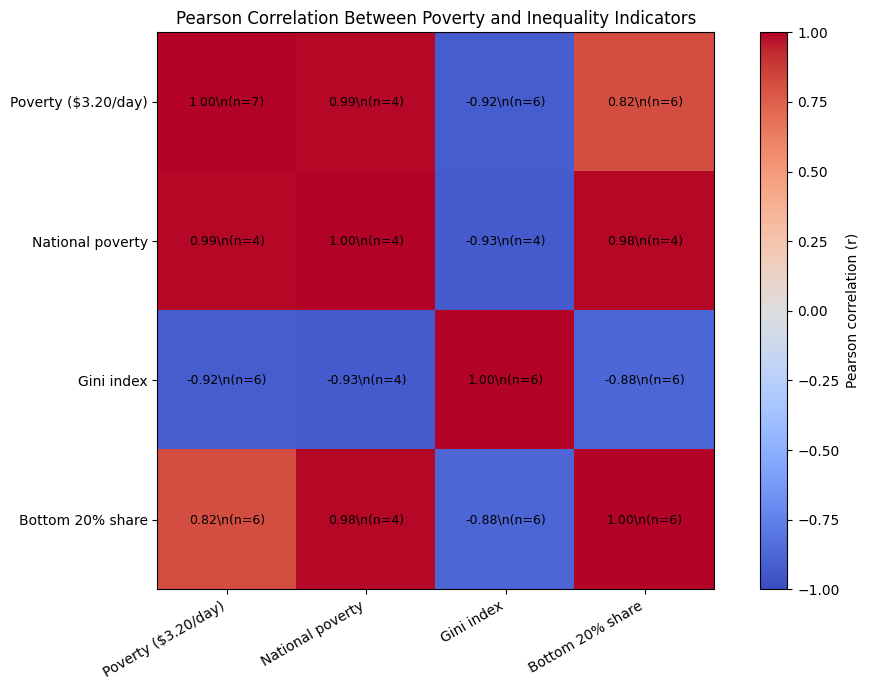

In [8]:

# Create a year-by-indicator table for correlation analysis
indicator_year_data = {}

for indicator in selected_indicators:
    subset = analysis_data[analysis_data["Indicator Name"] == indicator]
    indicator_year_data[indicator] = subset.set_index("Year")["Value"]

indicator_wide = pd.DataFrame(indicator_year_data)

# Pearson correlation uses only years where both indicators have observations
correlation_matrix = indicator_wide.corr(method="pearson")
pair_count_matrix = indicator_wide.notna().astype(int).T.dot(
    indicator_wide.notna().astype(int)
)

print("Pearson correlation matrix:")
display(correlation_matrix.round(3))

print("Number of paired years used for each correlation:")
display(pair_count_matrix)

# Heatmap-style correlation plot using Matplotlib
fig, ax = plt.subplots(figsize=(10, 7))
image = ax.imshow(correlation_matrix, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(selected_indicators)))
ax.set_yticks(range(len(selected_indicators)))
short_names = [
    "Poverty ($3.20/day)",
    "National poverty",
    "Gini index",
    "Bottom 20% share"
]
ax.set_xticklabels(short_names, rotation=30, ha="right")
ax.set_yticklabels(short_names)

for i in range(len(selected_indicators)):
    for j in range(len(selected_indicators)):
        value = correlation_matrix.iloc[i, j]
        count = pair_count_matrix.iloc[i, j]
        if pd.notna(value):
            ax.text(j, i, f"{value:.2f}\\n(n={count})",
                    ha="center", va="center", fontsize=9)

ax.set_title("Pearson Correlation Between Poverty and Inequality Indicators")
fig.colorbar(image, ax=ax, label="Pearson correlation (r)")
plt.tight_layout()
plt.show()



### 4.4 Scatter plots for selected relationships

Scatter plots help inspect the direction and approximate linear pattern between two indicators. The fitted line is a descriptive least-squares trend line, not evidence of a causal relationship.


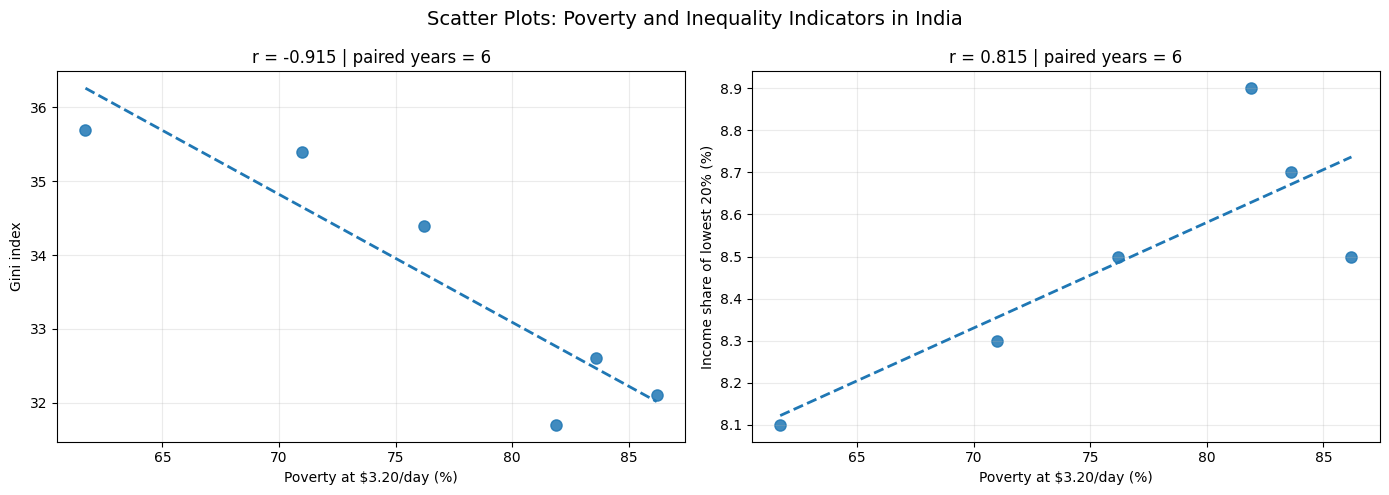

In [9]:

# Plot two substantively relevant pairs using only matching years
scatter_pairs = [
    (selected_indicators[0], selected_indicators[2],
     "Poverty at $3.20/day (%)", "Gini index"),
    (selected_indicators[0], selected_indicators[3],
     "Poverty at $3.20/day (%)", "Income share of lowest 20% (%)")
]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, (x_indicator, y_indicator, x_label, y_label) in zip(axes, scatter_pairs):
    pair = indicator_wide[[x_indicator, y_indicator]].dropna()

    ax.scatter(pair[x_indicator], pair[y_indicator], s=65, alpha=0.85)

    if len(pair) >= 2 and pair[x_indicator].nunique() > 1:
        slope, intercept = np.polyfit(pair[x_indicator], pair[y_indicator], 1)
        x_line = np.linspace(pair[x_indicator].min(), pair[x_indicator].max(), 100)
        ax.plot(x_line, slope * x_line + intercept, linestyle="--", linewidth=2)

    r_value = pair[x_indicator].corr(pair[y_indicator]) if len(pair) >= 2 else np.nan
    ax.set_title(f"r = {r_value:.3f} | paired years = {len(pair)}")
    ax.set_xlabel(x_label)
    ax.set_ylabel(y_label)
    ax.grid(alpha=0.25)

fig.suptitle("Scatter Plots: Poverty and Inequality Indicators in India", fontsize=14)
plt.tight_layout()
plt.show()



### 4.5 Comparison of first and latest available observations

A grouped bar chart makes the change between the first and latest available observation easier to compare. The years differ across indicators, so this is a comparison of each indicator's available endpoints—not a comparison over one common time period.


,Indicator,First,Latest,First year,Latest year
0,Poverty headcount ratio at $3.20 a day (2011 P...,88.7,61.7,1977,2011
1,Poverty headcount ratio at national poverty li...,45.3,21.9,1993,2011
2,Gini index (World Bank estimate),32.1,35.7,1983,2011
3,Income share held by lowest 20%,8.5,8.1,1983,2011


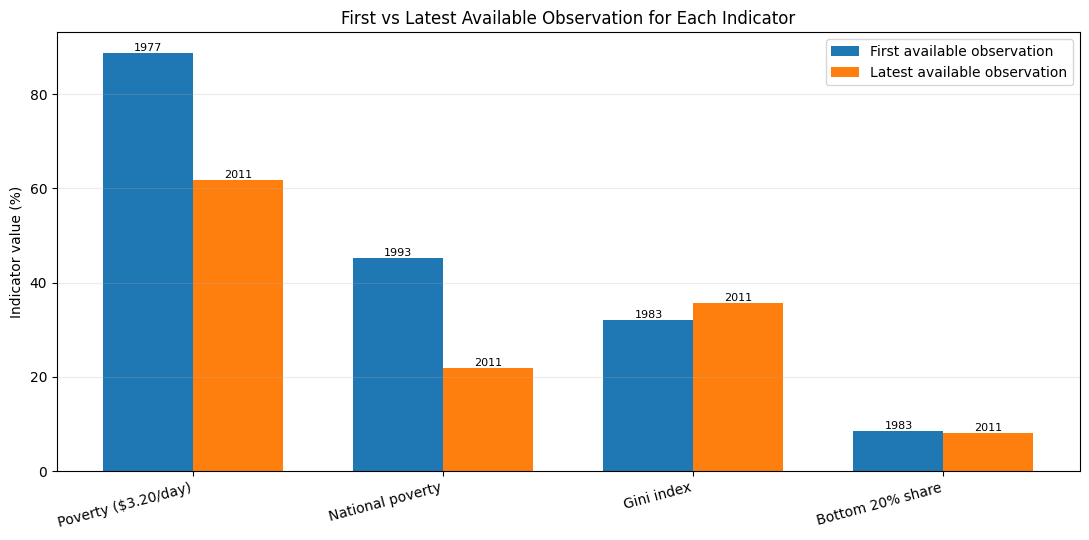

In [10]:

# Build endpoint comparison data from the available observations
endpoint_rows = []

for indicator in selected_indicators:
    subset = analysis_data[analysis_data["Indicator Name"] == indicator].sort_values("Year")
    if not subset.empty:
        endpoint_rows.append({
            "Indicator": indicator,
            "First": subset.iloc[0]["Value"],
            "Latest": subset.iloc[-1]["Value"],
            "First year": int(subset.iloc[0]["Year"]),
            "Latest year": int(subset.iloc[-1]["Year"])
        })

endpoint_df = pd.DataFrame(endpoint_rows)
display(endpoint_df.round(2))

x = np.arange(len(endpoint_df))
width = 0.36

fig, ax = plt.subplots(figsize=(11, 5.5))
ax.bar(x - width/2, endpoint_df["First"], width,
       label="First available observation")
ax.bar(x + width/2, endpoint_df["Latest"], width,
       label="Latest available observation")

ax.set_xticks(x)
ax.set_xticklabels(
    ["Poverty ($3.20/day)", "National poverty", "Gini index", "Bottom 20% share"],
    rotation=15, ha="right"
)
ax.set_ylabel("Indicator value (%)")
ax.set_title("First vs Latest Available Observation for Each Indicator")
ax.legend()
ax.grid(axis="y", alpha=0.25)

for i, row in endpoint_df.iterrows():
    ax.text(i - width/2, row["First"], f'{row["First year"]}',
            ha="center", va="bottom", fontsize=8)
    ax.text(i + width/2, row["Latest"], f'{row["Latest year"]}',
            ha="center", va="bottom", fontsize=8)

plt.tight_layout()
plt.show()



## 5. Interpretation of Results

### 5.1 Poverty Trend

The poverty headcount ratio at $3.20 a day declined from **88.7% in 1977** to **61.7% in 2011**, a decrease of **27.0 percentage points**. The national poverty headcount ratio declined from **45.3% in 1993** to **21.9% in 2011**, a decrease of **23.4 percentage points**.

For a percentage indicator, the absolute change is expressed in percentage points.

**Percentage-Point Change:**

$$
\boxed{
\text{Percentage-point change}
=
\text{Latest percentage}
-
\text{First percentage}
}
$$

This is different from percentage change, which measures the relative change compared with the initial value.

**Percentage Change:**

$$
\boxed{
\%\text{ Change}
=
\frac{\text{Latest value}-\text{First value}}
{\text{First value}}
\times 100
}
$$

### 5.2 Income inequality

The Gini index increased from **32.1 in 1983** to **35.7 in 2011** in the available observations. A higher Gini value indicates greater income inequality. The income share held by the lowest 20% changed from **8.5% in 1983** to **8.1% in 2011**. These observations suggest that declining poverty ratios did not necessarily coincide with a reduction in measured income inequality.

### 5.3 Descriptive statistics and frequency distribution

The descriptive-statistics table summarises the centre and spread of each indicator. The mean gives the arithmetic average, the median gives the middle observation, the range shows the difference between the maximum and minimum, and the sample standard deviation measures dispersion around the mean.

The frequency tables group the available observations into value intervals. They help show where observations are concentrated. Since the number of observations is small and survey years are irregular, these tables should be interpreted as summaries of the recorded observations—not as annual distributions for every year.

### 5.4 Correlation results

The Pearson correlation matrix and scatter plots describe how the selected indicators move together in the years where both values are available. The displayed paired-year counts are important: a coefficient calculated from only a few survey years can change substantially if one observation changes.

A negative correlation between poverty and the Gini index, for example, would mean that the two indicators moved in opposite directions across the paired observations. It would **not** mean that poverty reduction caused inequality to rise or fall. Economic growth, employment, public policy, demographic changes, survey methods and other factors may influence these indicators.

### 5.5 Limitations

- The dataset contains many missing values; missing observations were excluded rather than replaced with zero.
- The selected indicators are available for different and irregular years.
- Correlation is based on pairwise overlapping years, so sample sizes differ between indicator pairs.
- The analysis is descriptive and exploratory. It does not identify causal effects.
- The $3.20/day poverty measure and national poverty-line measure use different poverty definitions and should not be treated as directly interchangeable.



## 6. Conclusions

The analysis of the available World Bank observations for India shows a decline in both selected poverty headcount measures over their respective observation periods. At the same time, the available Gini-index observations increased, while the income share held by the lowest 20% changed only slightly.

Descriptive statistics, frequency distributions, trend charts, scatter plots and Pearson correlation provide complementary ways to summarise the dataset. Together, they show why poverty and inequality should be examined as related but distinct dimensions of economic well-being.

The findings must be interpreted with care because the data is sparse and does not cover every year. The results describe patterns in the available observations; they do not prove that one indicator caused a change in another. A future study could use more recent and more complete survey data to examine these relationships in greater depth.


## 5. Main Results

In the supplied workbook, the available India observations include:

| Indicator | First available observation | Latest available observation |
|---|---:|---:|
| Poverty headcount ratio at $3.20 a day (2011 PPP) | 1977: 88.7% | 2011: 61.7% |
| Poverty headcount ratio at national poverty lines | 1993: 45.3% | 2011: 21.9% |
| Gini index (World Bank estimate) | 1983: 32.1 | 2011: 35.7 |
| Income share held by lowest 20% | 1983: 8.5% | 2011: 8.1% |

The values above are the first and latest available observations in this workbook for the selected India indicators.